# 05 — Fusion multi-blocs : textes, code, difficulté et TF-IDF

Jusqu'ici, une seule colonne était utilisée : la description. On ajoute ici l'information des autres colonnes, chacune
encodée par un modèle adapté :

| Bloc | Colonne source | Encodage | Dimension |
|---|---|---|---|
| `description` | `prob_desc_description` | Sentence-BERT `all-mpnet-base-v2` | 768 |
| `input_spec` | `prob_desc_input_spec` | Sentence-BERT | 768 |
| `notes` | `prob_desc_notes` (vide si absente) | Sentence-BERT | 768 |
| `code` | `source_code` | **UniXcoder** (`microsoft/unixcoder-base`, encodeur spécialisé code) | 768 |
| `difficulty` | `difficulty` | one-hot de 5 tranches de quantiles + « inconnue » (`-1`/NaN) | 6 |
| `tfidf_desc` *(section 4)* | `prob_desc_description` lemmatisée | TF-IDF mots | ~1 800 (creux) |
| `tfidf_code` *(section 4)* | `source_code` | TF-IDF identifiants | ~1 700 (creux) |

**Deux façons de combiner les blocs**, toutes deux à base de régressions logistiques :
1. **Concaténation** : un seul vecteur (~3 000 colonnes denses), standardisé colonne par colonne, puis 8 régressions
   logistiques. Un coefficient par colonne, mais une seule force de régularisation `C` pour tous les blocs.
2. **Stacking** : un modèle par bloc (niveau 1). Puis, pour chaque tag, une régression logistique (niveau 2) sur les
   probabilités *out-of-fold* des blocs. Le niveau 2 apprend **explicitement le poids de chaque bloc pour chaque tag**.

**Protocole** (identique aux notebooks 03 et 04)
- **Sélection** : validation croisée à 5 folds sur train + val, critère Macro-AP.
- **Évaluation finale** : entraînement sur train, seuils réglés sur val, test évalué une seule fois.
- **Benchmark** : la régression logistique sur la description seule (notebook 03, Macro-F1 test 0.612).

In [1]:
import logging
import sys
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import TARGET_TAGS, FeatureConfig, LogRegConfig, TuningConfig
from src.dataset import load_modeling_data
from src.embeddings import load_encoder
from src.evaluate import (
    apply_thresholds,
    bootstrap_macro_f1_diff,
    global_metrics,
    per_tag_metrics,
    tune_thresholds,
)
from src.features import TFIDF_BLOCKS, build_blocks, concat_rows, encode_blocks, subset_blocks
from src.fusion import ConcatTagger, StackingTagger
from src.linear import build_logreg
from src.tuning import cross_val_scores

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
sns.set_theme(style="whitegrid", context="notebook")

FEATURE_CFG = FeatureConfig()
TUNING_CFG = TuningConfig()

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 12:57:12.991000 43084 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 1. Construction des blocs de features

In [2]:
data = load_modeling_data()
# Embeddings mis en cache dans data/embeddings/ (un fichier par modèle et colonne) : calculés une seule fois
blocks = build_blocks(data.df, FEATURE_CFG)
x, y = {name: subset_blocks(blocks, p) for name, p in data.positions.items()}, data.y
x_dev, y_dev = concat_rows(x["train"], x["val"]), np.vstack([y["train"], y["val"]])

DENSE_BLOCKS = [name for name in blocks if name not in TFIDF_BLOCKS]
pd.Series(
    {name: blocks[name].shape[1] if name in DENSE_BLOCKS else "texte brut → TF-IDF" for name in blocks},
    name="colonnes",
).to_frame().T

,description,input_spec,notes,code,difficulty,tfidf_code,tfidf_desc
colonnes,768,768,768,768,1,texte brut → TF-IDF,texte brut → TF-IDF


In [3]:
# Taux de valeurs manquantes par colonne source
df = data.df
pd.Series(
    {
        "input_spec vide": df["prob_desc_input_spec"].isna().mean(),
        "notes vides": df["prob_desc_notes"].isna().mean(),
        "difficulty inconnue (-1 / NaN)": (df["difficulty"].isna() | (df["difficulty"] <= 0)).mean(),
    }
).map("{:.1%}".format).to_frame("part")

,part
input_spec vide,0.7%
notes vides,27.1%
difficulty inconnue (-1 / NaN),1.0%


## 2. Choix de la régularisation pour la concaténation

Après standardisation, les ~3 000 colonnes sont à la même échelle. `C` doit être réglé, car la valeur du benchmark (C=1)
correspond à un seul bloc de 768 colonnes non standardisées.

In [4]:
def cv_score(make_model, names: list[str]) -> tuple[float, float]:
    """Macro-AP moyenne (et écart-type) en CV sur train+val, pour le modèle restreint aux blocs `names`."""
    scores = cross_val_scores(
        lambda xt, yt, xe, ye: make_model(names).fit(xt, yt).predict_proba(xe), x_dev, y_dev, TUNING_CFG.n_splits
    )
    return np.mean(scores), np.std(scores)


concat_c = pd.DataFrame(
    {
        C: cv_score(lambda names, C=C: ConcatTagger(names, C), DENSE_BLOCKS)
        for C in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1)
    },
    index=["cv_macro_ap", "cv_std"],
).T.rename_axis("C")
BEST_CONCAT_C = concat_c["cv_macro_ap"].idxmax()
print("C retenu pour la concaténation :", BEST_CONCAT_C)
concat_c.round(4)

C retenu pour la concaténation : 0.001


,cv_macro_ap,cv_std
C,,
0.0001,0.6468,0.0186
0.0003,0.6588,0.0170
0.0010,0.6639,0.0183
0.0030,0.6578,0.0189
0.0100,0.6411,0.0192
0.0300,0.6252,0.0199
0.1000,0.6128,0.0201


In [5]:
FUSIONS = {
    "concat": lambda names: ConcatTagger(names, BEST_CONCAT_C),
    "stacking": lambda names: StackingTagger(names, FEATURE_CFG),
}

## 3. Ablation par bloc (blocs d'embeddings et difficulté)

Trois lectures complémentaires, en Macro-AP de validation croisée :
- **bloc seul** : quelle information porte chaque bloc pris isolément ;
- **ajout cumulatif** : gain marginal de chaque bloc ajouté à la description ;
- **retrait d'un bloc** depuis le modèle complet : un bloc dont le retrait ne coûte rien est redondant.

In [6]:
start = time.perf_counter()
cumulative = [DENSE_BLOCKS[: i + 1] for i in range(len(DENSE_BLOCKS))]
leave_one_out = [[b for b in DENSE_BLOCKS if b != removed] for removed in DENSE_BLOCKS]
experiments = (
    [("seul", [b], b) for b in DENSE_BLOCKS]
    + [("cumulatif", names, "+ " + names[-1]) for names in cumulative]
    + [("retrait", names, "- " + removed) for names, removed in zip(leave_one_out, DENSE_BLOCKS)]
)
rows = []
for kind, names, label in experiments:
    for fusion, make_model in FUSIONS.items():
        mean, std = cv_score(make_model, names)
        rows.append({"type": kind, "blocs": label, "fusion": fusion, "cv_macro_ap": mean, "cv_std": std})
ablation = pd.DataFrame(rows)
print(f"Ablation : {time.perf_counter() - start:.0f}s")
ablation.pivot_table(index=["type", "blocs"], columns="fusion", values="cv_macro_ap", sort=False).round(4)

Ablation : 54s


fusion                   concat  stacking
type      blocs                          
seul      description    0.5905    0.5904
          input_spec     0.4093    0.4094
          notes          0.3731    0.3752
          code           0.4057    0.4030
          difficulty     0.1117    0.1103
cumulatif + description  0.5905    0.5904
          + input_spec   0.6171    0.6140
          + notes        0.6134    0.6170
          + code         0.6627    0.6540
          + difficulty   0.6639    0.6557
retrait   - description  0.5793    0.5775
          - input_spec   0.6553    0.6494
          - notes        0.6637    0.6543
          - code         0.6176    0.6243
          - difficulty   0.6627    0.6540

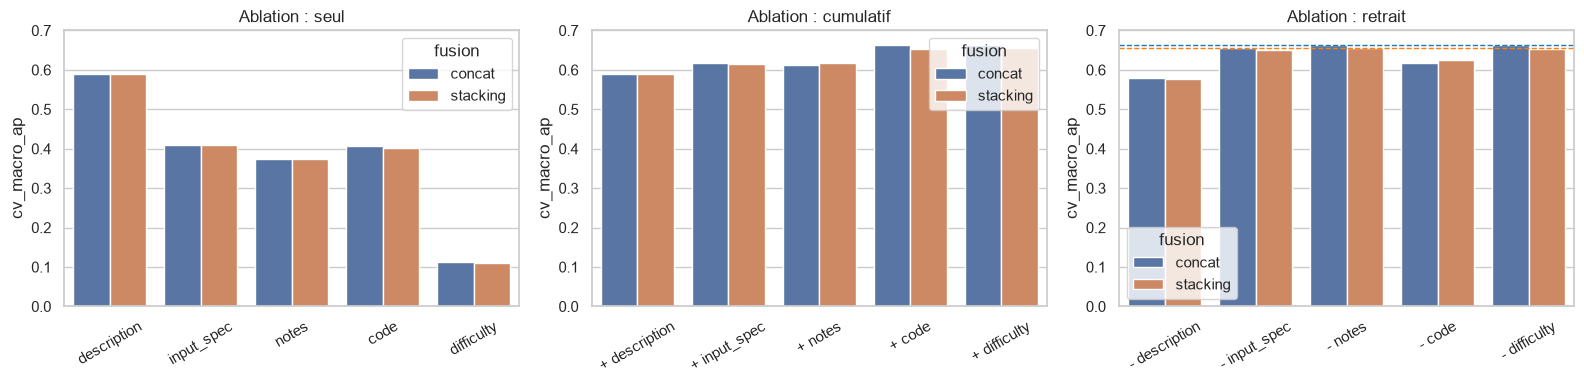

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, kind in zip(axes, ["seul", "cumulatif", "retrait"]):
    sub = ablation[ablation["type"] == kind]
    sns.barplot(data=sub, x="blocs", y="cv_macro_ap", hue="fusion", ax=ax)
    ax.set(title=f"Ablation : {kind}", xlabel="", ylim=(0, 0.7))
    ax.tick_params(axis="x", rotation=30)
full = ablation[(ablation["type"] == "cumulatif") & (ablation["blocs"] == "+ " + DENSE_BLOCKS[-1])]
for _, row in full.iterrows():
    axes[2].axhline(row["cv_macro_ap"], linestyle="--", linewidth=1, color="tab:blue" if row["fusion"] == "concat" else "tab:orange")
plt.tight_layout()
plt.show()

## 4. Blocs TF-IDF dans le stacking

Hypothèse (notebook 02) : un embedding moyenné **dilue** les termes rares et décisifs (`gcd`, `998244353`, *probability*),
qu'une TF-IDF garde chacun dans sa propre colonne. On ajoute donc deux blocs candidats **au stacking** :

| Bloc | Entrée | Traitement (appris sur le train de chaque fold) | Taille |
|---|---|---|---|
| `tfidf_desc` | description brute | nettoyage + **lemmatisation** → TF-IDF mots (`min_df=10`, stop words anglais) | ~1 800 |
| `tfidf_code` | code brut | TF-IDF identifiants (`min_df=5`, mots-clés Python exclus) | ~1 700 |

- **Chaque bloc TF-IDF a sa propre régression logistique de niveau 1**, qui gère bien les matrices creuses. Le niveau 2 ne
  reçoit qu'une probabilité de plus par tag et par bloc, si bien que les ~1 700 colonnes ne se mélangent jamais aux embeddings.
- **Pas de fuite** : le vocabulaire et l'IDF sont appris au `fit`, donc sur le train de chaque fold, jamais sur l'exemple prédit.
- **Concaténation non testée ici** : il faudrait mélanger matrices creuses et denses avec un seul `C`, ce qui pose
  exactement le problème d'échelle que le stacking évite.

In [8]:
# Régularisation des régressions logistiques TF-IDF : réglée bloc par bloc, chaque bloc seul
tfidf_c = pd.DataFrame(
    {
        C: {
            block: cv_score(
                lambda names, C=C: StackingTagger(names, replace(FEATURE_CFG, tfidf_code_C=C, tfidf_desc_C=C)), [block]
            )[0]
            for block in TFIDF_BLOCKS
        }
        for C in (0.1, 0.3, 1.0, 3.0, 10.0)
    }
).T.rename_axis("C")
TFIDF_CFG = replace(
    FEATURE_CFG, tfidf_code_C=tfidf_c["tfidf_code"].idxmax(), tfidf_desc_C=tfidf_c["tfidf_desc"].idxmax()
)
print(f"C retenus : tfidf_code={TFIDF_CFG.tfidf_code_C}, tfidf_desc={TFIDF_CFG.tfidf_desc_C}")
tfidf_c.round(4)

C retenus : tfidf_code=0.1, tfidf_desc=1.0


,tfidf_code,tfidf_desc
C,,
0.1,0.3176,0.5658
0.3,0.3174,0.5753
1.0,0.3110,0.5809
3.0,0.2957,0.5759
10.0,0.2756,0.5627


In [9]:
# Chaque bloc seul, à comparer à son équivalent embedding
alone = {name: cv_score(lambda names: StackingTagger(names, TFIDF_CFG), [name])[0] for name in ["description", "tfidf_desc", "code", "tfidf_code"]}
pd.Series(alone, name="cv_macro_ap (bloc seul)").round(4).to_frame()

,cv_macro_ap (bloc seul)
description,0.5904
tfidf_desc,0.5809
code,0.4030
tfidf_code,0.3176


In [10]:
# Ajout des blocs TF-IDF au stacking complet (embeddings + difficulté)
tfidf_variants = {
    "embeddings + difficulté": DENSE_BLOCKS,
    "+ tfidf_desc": DENSE_BLOCKS + ["tfidf_desc"],
    "+ tfidf_code": DENSE_BLOCKS + ["tfidf_code"],
    "+ tfidf_desc + tfidf_code": DENSE_BLOCKS + list(TFIDF_BLOCKS),
}
tfidf_ablation = pd.DataFrame(
    {label: cv_score(lambda names: StackingTagger(names, TFIDF_CFG), names) for label, names in tfidf_variants.items()},
    index=["cv_macro_ap", "cv_std"],
).T
BEST_VARIANT = tfidf_ablation["cv_macro_ap"].idxmax()
print("Variante retenue :", BEST_VARIANT)
tfidf_ablation.round(4)

Variante retenue : + tfidf_desc


,cv_macro_ap,cv_std
embeddings + difficulté,0.6557,0.0185
+ tfidf_desc,0.6626,0.0181
+ tfidf_code,0.6490,0.0191
+ tfidf_desc + tfidf_code,0.6588,0.0185


## 5. Évaluation finale sur le test

On compare le benchmark, les deux fusions sur les blocs denses, et le stacking avec la variante TF-IDF retenue en CV.

In [11]:
models = {
    "benchmark (description)": build_logreg(LogRegConfig()),
    "concat (embeddings + difficulté)": FUSIONS["concat"](DENSE_BLOCKS),
    "stacking (embeddings + difficulté)": FUSIONS["stacking"](DENSE_BLOCKS),
    f"stacking ({BEST_VARIANT})": StackingTagger(tfidf_variants[BEST_VARIANT], TFIDF_CFG),
}
BEST_MODEL = f"stacking ({BEST_VARIANT})"


def model_input(name: str, split: str):
    """Le benchmark ne lit que l'embedding de la description ; les fusions reçoivent tous les blocs."""
    return x[split]["description"] if name.startswith("benchmark") else x[split]


thresholds, predictions, fitted = {}, {}, {}
for name, model in models.items():
    fitted[name] = model.fit(model_input(name, "train"), y["train"])
    thresholds[name] = tune_thresholds(y["val"], model.predict_proba(model_input(name, "val")))
    predictions[name] = apply_thresholds(model.predict_proba(model_input(name, "test")), thresholds[name])

pd.DataFrame({name: global_metrics(y["test"], pred) for name, pred in predictions.items()}).T.round(3)

,micro_f1,macro_f1,hamming_loss,jaccard_samples
benchmark (description),0.554,0.612,0.083,0.532
concat (embeddings + difficulté),0.618,0.642,0.074,0.588
stacking (embeddings + difficulté),0.622,0.646,0.074,0.602
stacking (+ tfidf_desc),0.627,0.647,0.072,0.600


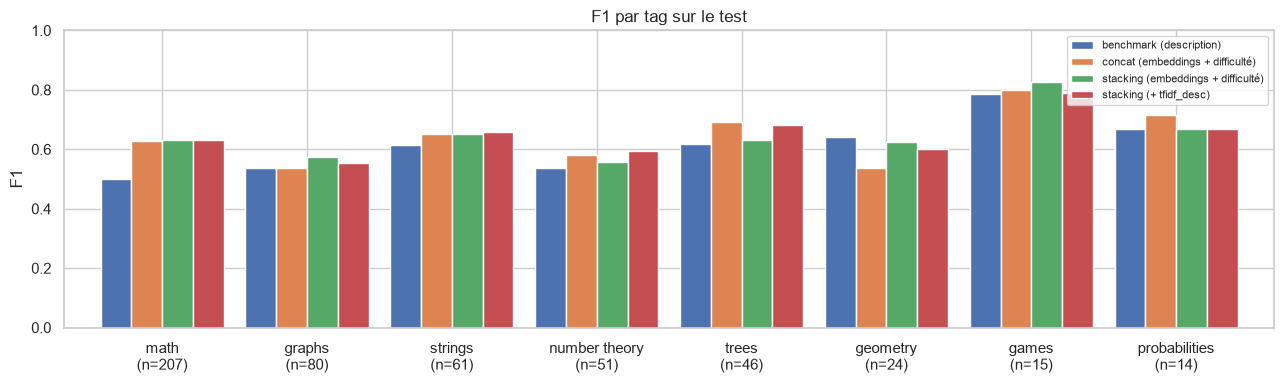

,math,graphs,strings,number theory,trees,geometry,games,probabilities
benchmark (description),0.50,0.54,0.61,0.54,0.62,0.64,0.79,0.67
concat (embeddings + difficulté),0.63,0.54,0.65,0.58,0.69,0.54,0.80,0.71
stacking (embeddings + difficulté),0.63,0.57,0.65,0.56,0.63,0.62,0.83,0.67
stacking (+ tfidf_desc),0.63,0.55,0.66,0.59,0.68,0.60,0.79,0.67


In [12]:
f1_by_tag = pd.DataFrame(
    {name: per_tag_metrics(y["test"], pred, TARGET_TAGS)["f1"] for name, pred in predictions.items()}
)
support = y["test"].sum(axis=0)

fig, ax = plt.subplots(figsize=(13, 4))
f1_by_tag.plot.bar(ax=ax, rot=0, width=0.85)
ax.set(title="F1 par tag sur le test", ylabel="F1", ylim=(0, 1))
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(TARGET_TAGS, support)])
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()
f1_by_tag.T.round(2)

In [13]:
pairs = [
    ("stacking (embeddings + difficulté)", "benchmark (description)"),
    ("concat (embeddings + difficulté)", "benchmark (description)"),
    (BEST_MODEL, "benchmark (description)"),
    (BEST_MODEL, "stacking (embeddings + difficulté)"),
]
pd.DataFrame(
    {
        f"{a} - {b}": bootstrap_macro_f1_diff(y["test"], predictions[a], predictions[b], TUNING_CFG.n_bootstrap)
        for a, b in pairs
        if a != b
    }
).T.round(3)

,diff_mean,ci_low,ci_high,p_a_better
stacking (embeddings + difficulté) - benchmark (description),0.034,0.003,0.065,0.985
concat (embeddings + difficulté) - benchmark (description),0.030,-0.003,0.064,0.969
stacking (+ tfidf_desc) - benchmark (description),0.035,-0.001,0.073,0.974
stacking (+ tfidf_desc) - stacking (embeddings + difficulté),0.001,-0.023,0.028,0.521


In [14]:
# Précision / rappel du meilleur modèle par tag
per_tag_metrics(y["test"], predictions[BEST_MODEL], TARGET_TAGS).round(2)

,precision,recall,f1,support
math,0.57,0.71,0.63,207
graphs,0.52,0.60,0.55,80
strings,0.56,0.80,0.66,61
number theory,0.55,0.65,0.59,51
trees,0.67,0.70,0.68,46
geometry,0.46,0.88,0.60,24
games,0.72,0.87,0.79,15
probabilities,0.62,0.71,0.67,14


### Comparaison à la stratégie triviale « toujours oui »

Prédire un tag pour **tous** les exercices donne un rappel de 100 %, mais une précision égale à la prévalence p du tag,
soit un F1 de 2p / (1 + p). C'est le plancher à dépasser pour chaque tag : un F1 se lit par rapport à cette valeur.

In [15]:
always_yes = np.ones_like(y["test"])
trivial = per_tag_metrics(y["test"], always_yes, TARGET_TAGS)
best = per_tag_metrics(y["test"], predictions[BEST_MODEL], TARGET_TAGS)
pd.DataFrame(
    {
        "prévalence test": trivial["precision"],  # précision de « toujours oui » = prévalence
        "F1 « toujours oui »": trivial["f1"],
        "F1 meilleur modèle": best["f1"],
        "gain (x)": best["f1"] / trivial["f1"],
    }
).round(2)

,prévalence test,F1 « toujours oui »,F1 meilleur modèle,gain (x)
math,0.29,0.44,0.63,1.42
graphs,0.11,0.20,0.55,2.80
strings,0.08,0.16,0.66,4.24
number theory,0.07,0.13,0.59,4.53
trees,0.06,0.12,0.68,5.71
geometry,0.03,0.06,0.60,9.38
games,0.02,0.04,0.79,19.46
probabilities,0.02,0.04,0.67,17.62


In [16]:
pd.DataFrame(
    {
        "toujours oui (8 tags)": global_metrics(y["test"], always_yes),
        BEST_MODEL: global_metrics(y["test"], predictions[BEST_MODEL]),
    }
).T.round(3)

,micro_f1,macro_f1,hamming_loss,jaccard_samples
toujours oui (8 tags),0.158,0.149,0.914,0.086
stacking (+ tfidf_desc),0.627,0.647,0.072,0.600


## 6. Quel bloc compte pour quel tag ?

Coefficients du niveau 2 du meilleur stacking : pour chaque tag, le poids donné au logit de chaque bloc. Les entrées sont
toutes des logits de probabilités, donc **les coefficients sont directement comparables entre blocs**. C'est précisément
ce que la concaténation ne permet pas de lire.

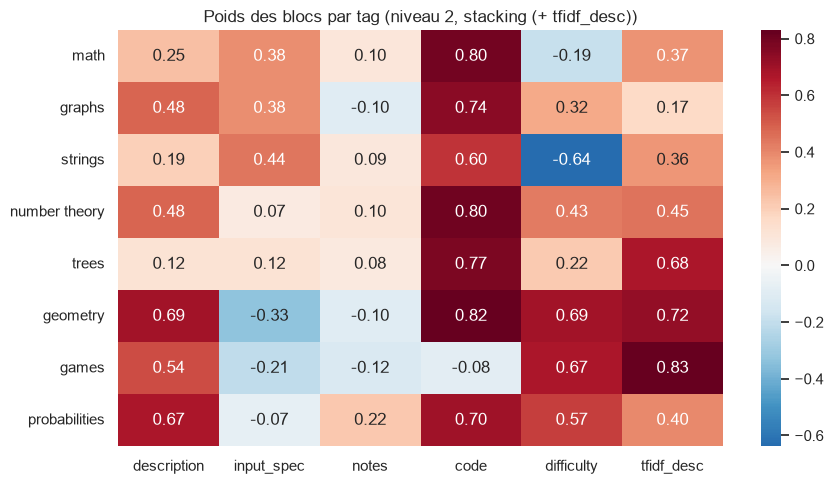

In [17]:
coefs = fitted[BEST_MODEL].meta_coefficients(TARGET_TAGS)
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(coefs, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title=f"Poids des blocs par tag (niveau 2, {BEST_MODEL})")
plt.tight_layout()
plt.show()

## 7. Latence d'inférence (contrainte : < 10 s par exemple)

Pipeline complet pour un exercice brut :
1. 3 encodages Sentence-BERT et 1 encodage UniXcoder ;
2. difficulté et textes bruts ;
3. stacking (dont la lemmatisation et la TF-IDF), puis seuils.

Le chargement des deux encodeurs est mesuré à part, car il n'est payé qu'une fois.

In [18]:
start = time.perf_counter()
text_encoder = load_encoder(FEATURE_CFG.text_model)
code_encoder = load_encoder(FEATURE_CFG.code_model, FEATURE_CFG.code_max_seq_length)
load_time = time.perf_counter() - start

model, th = fitted[BEST_MODEL], thresholds[BEST_MODEL]
test_df = data.df.iloc[data.positions["test"]]
encode_blocks(test_df.iloc[:1], text_encoder, code_encoder)  # warm-up

latencies = []
for i in range(50):
    start = time.perf_counter()
    features = encode_blocks(test_df.iloc[[i]], text_encoder, code_encoder)
    apply_thresholds(model.predict_proba(features), th)
    latencies.append(time.perf_counter() - start)

print(f"Chargement des encodeurs : {load_time:.1f}s (une fois)")
print(f"Latence par exemple : médiane {np.median(latencies) * 1000:.0f} ms, max {np.max(latencies) * 1000:.0f} ms")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14196.94it/s]

WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 61340.96it/s]

Chargement des encodeurs : 2.2s (une fois)
Latence par exemple : médiane 64 ms, max 121 ms


## 8. Constats

**Le multi-blocs apporte un gain net**

| Modèle | Macro-AP CV | Micro-F1 test | Macro-F1 test | Hamming | Jaccard |
|---|---|---|---|---|---|
| Benchmark (description seule) | 0.590 | 0.554 | 0.612 | 0.083 | 0.532 |
| Concaténation (C=0.001) | **0.664** | 0.618 | 0.642 | 0.074 | 0.588 |
| Stacking (embeddings + difficulté) | 0.656 | 0.622 | 0.646 | 0.074 | **0.602** |
| Stacking + `tfidf_desc` | 0.663 | **0.627** | **0.647** | **0.072** | 0.600 |

- **Stacking contre benchmark** : +3,4 points de Macro-F1 sur le test, IC 95 % bootstrap [+0,3 ; +6,5]. Le Micro-F1 gagne 7 points.
- **Concaténation et stacking sont équivalents.** Leurs écarts (≤ 0,008 en CV, ≤ 0,005 sur le test) sont bien plus petits que
  l'écart-type entre folds (~0,02). Le stacking a l'avantage d'être **lisible** (section 6).
- *Note technique* : les embeddings restent en float32. L'ancienne version les convertissait en float64 en les concaténant à la
  difficulté, d'où des écarts ≤ 0,002 avec la version précédente de ce notebook.

**Ablation : ce que chaque bloc apporte** (coût en Macro-AP CV quand on le retire du modèle complet, concaténation / stacking)
- `description` : -0,085 / -0,078. C'est le socle, indispensable.
- `code` (UniXcoder) : -0,046 / -0,031. C'est **le 2e bloc le plus utile**, alors qu'il est faible pris seul (0,40). Il apporte une
  information **complémentaire** de l'énoncé.
- `input_spec` : -0,009 / -0,006. Gain modeste mais réel (« n vertices and m edges »…).
- `difficulty` : -0,001 / -0,002. Quasi neutre.
- `notes` : 0,000 / -0,001. **Redondant** avec la description.

**Blocs TF-IDF (stacking)**

| Bloc seul (Macro-AP CV) | Embedding | TF-IDF |
|---|---|---|
| Description | 0.590 (SBERT) | 0.581 |
| Code | **0.403** (UniXcoder) | 0.318 |

| Stacking (Macro-AP CV) | |
|---|---|
| Embeddings + difficulté | 0.656 |
| + `tfidf_desc` | **0.663** |
| + `tfidf_code` | 0.649 |
| + les deux | 0.659 |

- **La TF-IDF de description, seule, fait presque jeu égal avec SBERT** (0.581 contre 0.590). Ajoutée au stacking, elle apporte
  **+0,007 en CV**. Le niveau 2 lui donne un poids réel, souvent supérieur à celui de l'embedding SBERT de la description :
  `games` 0.83, `geometry` 0.72, `trees` 0.68. C'est le signal lexical (*play optimally*, *rooted*, *polygon*) que
  l'embedding dilue.
- **Sur le test, ce gain ne se confirme pas** : Macro-F1 de 0.647 contre 0.646, IC 95 % [-0,023 ; +0,028]. Il reste plus petit
  que le bruit d'un test de 726 exemples. Le gain est cohérent en CV, mais trop faible pour être démontré ici.
- **La TF-IDF du code n'aide pas, et dégrade même légèrement** (-0,007 en CV). Seule, elle est nettement sous UniXcoder
  (0.32 contre 0.40). Hypothèses :
  - la TF-IDF ne voit que des tokens isolés, sans structure (boucles, appels), là où UniXcoder encode le code en contexte ;
  - les identifiants utiles (`gcd`, `visited`…) sont rares, noyés parmi les noms de variables propres à chaque auteur ;
  - les tokens caractéristiques sont partagés par plusieurs tags (`pow` pour `math`, `number theory` et `probabilities`).
- **Réglages** : `C` de régression logistique propre à chaque bloc TF-IDF (0,1 pour le code, 1 pour la description), choisi en CV.

**Quel bloc compte pour quel tag** (niveau 2 du meilleur stacking)
- **Le code (UniXcoder) est le bloc le plus lourd pour 7 tags sur 8** (poids de 0,60 à 0,82). L'exception est `games` (-0,08),
  qui repose sur la description et sa TF-IDF.
- **`math`** : code 0,80 contre 0,25 pour la description. La notion mathématique est dans la solution, pas dans l'énoncé.
- La difficulté a des signes cohérents avec l'EDA : positive pour `geometry`, `games` et `probabilities` (exercices plus durs),
  négative pour `strings` (exercices plus faciles).

**Latence** : 61 ms en médiane par exemple (121 ms au maximum), lemmatisation et TF-IDF comprises, plus 2,2 s de chargement
des encodeurs une seule fois. On est très loin de la limite de 10 s.

**Pistes**
1. **Retirer `notes` et `tfidf_code`** : apport nul ou négatif, modèle plus simple, et un encodage SBERT de moins à l'inférence.
2. Régler les seuils sur les prédictions out-of-fold (≈ 4 100 exemples) plutôt que sur la seule validation (725), pour
   stabiliser `games` et `probabilities` (~15 positifs en test).
3. Valider le gain de `tfidf_desc` par **validation croisée répétée** (plusieurs graines de découpage), le test seul étant trop
   petit pour trancher un écart de 0,007.